# Explainable Fake News Detection System
## 1. Dataset Understanding

In [1]:
import pandas as pd
import numpy as np

In [8]:
df = pd.read_csv(
    r"C:\Users\Justina\OneDrive\Desktop\ML_project\explainable-fake-news-detection\data\WELFake_Dataset.csv"
)

In [9]:
df.head()


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [11]:
df.shape

(72134, 4)

In [12]:
df.columns

Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='str')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 2.2 MB


In [14]:
df['label'].value_counts()

label
1    37106
0    35028
Name: count, dtype: int64

In [15]:
df['label'].unique()

array([1, 0])

In [16]:
df.isnull().sum()

Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(597)

In [18]:
(df.isnull().sum() / len(df)) * 100

Unnamed: 0    0.000000
title         0.773560
text          0.054066
label         0.000000
dtype: float64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df[['title', 'text', 'label']].duplicated().sum()

np.int64(8456)

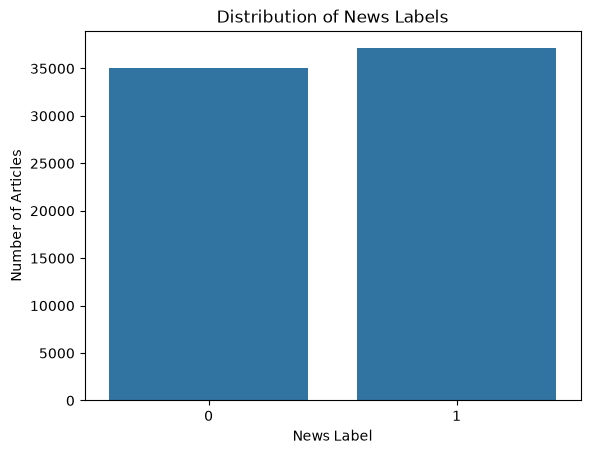

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='label')

plt.title("Distribution of News Labels")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")

plt.show()

### Observation – Class Distribution

The dataset contains 72,134 news articles divided into two
categories: 0 and 1.

- Label 0: 35,028 articles (48.56%)
- Label 1: 37,106 articles (51.44%)

The dataset is relatively balanced, with a small difference
between the two classes. Therefore, no immediate class
balancing technique is required.

In [24]:
df[df['title'].isnull() & df['text'].notnull()].head()

,Unnamed: 0,title,text,label
1,1,NaN,Did they post their votes for Hillary already?,1
43,43,NaN,True. Hillary needs a distraction and what bet...,1
162,162,NaN,All eyes on Electoral delegates. The People kn...,1
185,185,NaN,Cool,1
269,269,NaN,A leading US senator: US Supporting War in Syr...,1


In [26]:
df[df['title'].isnull() & df['text'].isnull()]

,Unnamed: 0,title,text,label


In [27]:
df[df['title'].isnull() & df['text'].isnull()].shape

(0, 4)

In [25]:
df[df['text'].isnull() & df['title'].notnull()].head()

,Unnamed: 0,title,text,label
2457,2457,Après le succès de « Mariés au premier regard ...,NaN,1
3534,3534,Elections US : les premières estimations donne...,NaN,1
3709,3709,110% des Américains assurent qu’ils continuero...,NaN,1
5612,5612,Des millions d’Américains recherchent massivem...,NaN,1
6270,6270,Vladimir Poutine est élu 45e Président des Eta...,NaN,1


In [28]:
df_clean = df.dropna(subset=['text'])

In [29]:
df_clean.isnull().sum()

Unnamed: 0      0
title         558
text            0
label           0
dtype: int64

In [30]:
df_clean.duplicated(subset=['title', 'text', 'label']).sum()

np.int64(8456)

In [31]:
df_clean = df_clean.drop_duplicates(
    subset=['title', 'text', 'label']
)

In [32]:
print("Shape after removing duplicates:", df_clean.shape)

print(
    "Remaining duplicates:",
    df_clean.duplicated(subset=['title', 'text', 'label']).sum()
)

Shape after removing duplicates: (63639, 4)
Remaining duplicates: 0


In [33]:
df_clean = df_clean.drop(columns=['Unnamed: 0'])

In [34]:
df_clean.columns

Index(['title', 'text', 'label'], dtype='str')

In [36]:
df_clean['title'].fillna('')

0        LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1                                                         
2        UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3        Bobby Jindal, raised Hindu, uses story of Chri...
4        SATAN 2: Russia unvelis an image of its terrif...
                               ...                        
72127    WIKILEAKS EMAIL SHOWS CLINTON FOUNDATION FUNDS...
72129    Russians steal research on Trump in hack of U....
72130     WATCH: Giuliani Demands That Democrats Apolog...
72131    Migrants Refuse To Leave Train At Refugee Camp...
72132    Trump tussle gives unpopular Mexican leader mu...
Name: title, Length: 63639, dtype: str

In [37]:
df_clean['content'] = (
    df_clean['title'].fillna('') + ' ' +
    df_clean['text'].fillna('')
)

In [38]:
df_clean[['title', 'text', 'content']].head()

,title,text,content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
1,NaN,Did they post their votes for Hillary already?,Did they post their votes for Hillary already?
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",SATAN 2: Russia unvelis an image of its terrif...


In [39]:
df_clean['content'].isnull().sum()

np.int64(0)